In [3]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
import pandas as pd
from scipy.linalg import svd

# 1) Base de datos de estudiantes (tomada de la tabla de la actividad)
data = {
    "Estudiante": [
        "Lucía",
        "Pedro",
        "Inés",
        "Luis",
        "Andrés",
        "Ana",
        "Carlos",
        "José",
        "Sonia",
        "María",
    ],
    "Matemáticas": [7.0, 7.5, 7.6, 5.0, 6.0, 7.8, 6.3, 7.9, 6.0, 6.8],
    "Ciencias": [6.5, 9.4, 9.2, 6.5, 6.0, 9.6, 6.4, 9.7, 6.0, 7.2],
    "Español": [9.2, 7.3, 8.0, 6.5, 7.8, 7.7, 8.2, 7.5, 6.5, 8.7],
    "Historia": [8.6, 7.0, 8.0, 7.0, 8.9, 8.0, 9.0, 8.0, 5.5, 9.0],
    "EdFísica": [8.0, 7.0, 7.5, 9.0, 7.3, 6.5, 7.2, 6.0, 8.7, 7.0],
}

estudiantes_df = pd.DataFrame(data)
etiquetas = estudiantes_df["Estudiante"]
A = estudiantes_df.drop(["Estudiante"], axis=1).values

print("Matriz A (10x5):\n", A)

Matriz A (10x5):
 [[7.  6.5 9.2 8.6 8. ]
 [7.5 9.4 7.3 7.  7. ]
 [7.6 9.2 8.  8.  7.5]
 [5.  6.5 6.5 7.  9. ]
 [6.  6.  7.8 8.9 7.3]
 [7.8 9.6 7.7 8.  6.5]
 [6.3 6.4 8.2 9.  7.2]
 [7.9 9.7 7.5 8.  6. ]
 [6.  6.  6.5 5.5 8.7]
 [6.8 7.2 8.7 9.  7. ]]


In [2]:
# Descomposición en valores singulares
U, s, VT = svd(A)

print("Valores singulares (s):", np.round(s, 4))

# Construir la matriz Sigma de tamaño (10, 5)
Sigma = np.zeros((A.shape[0], A.shape[1]))
Sigma[: A.shape[1], : A.shape[1]] = np.diag(s)

# Comprobación de reconstrucción: A ≈ U * Sigma * VT
B = U.dot(Sigma.dot(VT))
print(
    "Reconstrucción correcta (error máximo):", np.max(np.abs(A - B))
)  # ~9.77e-15

Valores singulares (s): [53.2134  5.3563  3.8056  1.469   0.478 ]
Reconstrucción correcta (error máximo): 1.509903313490213e-14


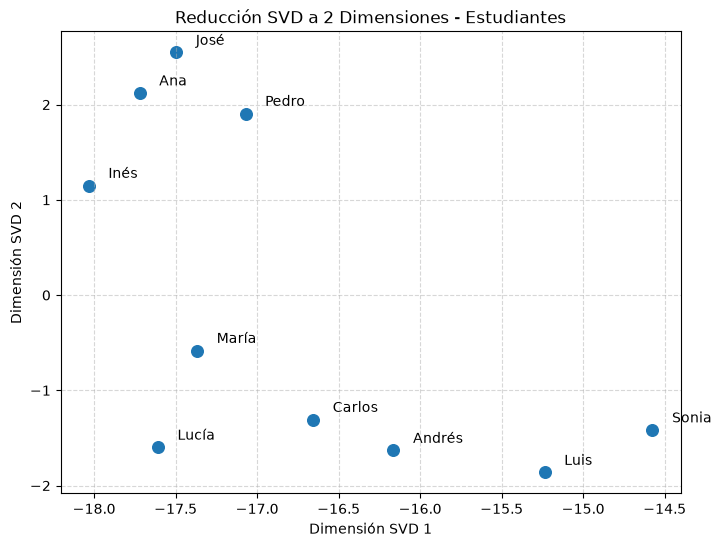

In [4]:
# Reducción a 2 dimensiones
n_elements_2 = 2
UReduced2 = U[:, :n_elements_2]
SigmaReduced2 = np.diag(s[:n_elements_2])
VTReduced2 = VT[:n_elements_2, :]

# Aproximación de rango 2 y proyección de estudiantes a 2D
AReduced2 = UReduced2.dot(SigmaReduced2.dot(VTReduced2))
T2 = UReduced2.dot(SigmaReduced2)

x2 = T2[:, 0]
y2 = T2[:, 1]

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(x2, y2, s=70)

for i, txt in enumerate(etiquetas):
  ax.annotate(txt, (x2[i] + 0.12, y2[i] + 0.08), fontsize=10)

ax.set_title("Reducción SVD a 2 Dimensiones - Estudiantes")
ax.set_xlabel("Dimensión SVD 1")
ax.set_ylabel("Dimensión SVD 2")
ax.grid(True, linestyle="--", alpha=0.5)
plt.show()

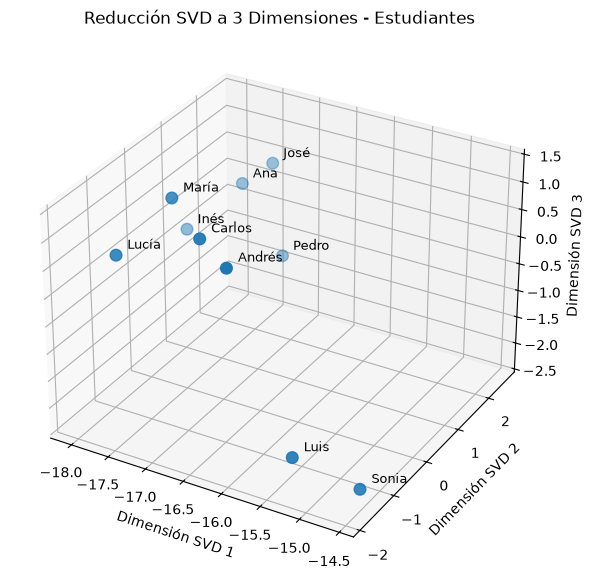

In [5]:
# Reducción a 3 dimensiones
n_elements_3 = 3
UReduced3 = U[:, :n_elements_3]
SigmaReduced3 = np.diag(s[:n_elements_3])
VTReduced3 = VT[:n_elements_3, :]

# Aproximación de rango 3 y proyección de estudiantes a 3D
AReduced3 = UReduced3.dot(SigmaReduced3.dot(VTReduced3))
T3 = UReduced3.dot(SigmaReduced3)

x3 = T3[:, 0]
y3 = T3[:, 1]
z3 = T3[:, 2]

fig = plt.figure(figsize=(9, 7))
ax3 = fig.add_subplot(111, projection="3d")
ax3.scatter(x3, y3, z3, s=70)

for i, txt in enumerate(etiquetas):
  ax3.text(x3[i] + 0.10, y3[i] + 0.10, z3[i] + 0.10, txt, fontsize=9)

ax3.set_title("Reducción SVD a 3 Dimensiones - Estudiantes")
ax3.set_xlabel("Dimensión SVD 1")
ax3.set_ylabel("Dimensión SVD 2")
ax3.set_zlabel("Dimensión SVD 3")
plt.show()